# The Spy Scares
### The Yariverse · argument map
Recreates an editable diagram and a self Contained HTML companion from the supplied essay. All 12 major themes are included; the HTML also preserves the full source text and citations.

**Evidence status:** News claims in the source are unverified. Research is summarized as reported by the essay, without implying causal effects on current hiring. The Cisco comparison and Machiavellianism reference lack developed supporting analysis in the source.

**Run:** Python 3 with `matplotlib` and `IPython` (`%pip install matplotlib ipython` if needed). Run all cells. Edit `CARDS` and `PALETTE` to customize. Outputs are saved to the current directory. No network access or original Word file is needed.

In [1]:
from pathlib import Path
import textwrap, html, re
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import display, SVG

# Edit these values to change the diagram and regenerate all exports.
PALETTE = {"baby": "#C9DFF2", "ivory": "#F7F3E8", "slate": "#293D52", "dusty": "#A9B8C5"}
OUTPUT_DIR = Path(".")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CARDS = [('01', 'The controversy', 'The draft describes alleged misconduct, an investigation and a resignation. Its November 2026 news claims require independent verification.', 'News claims in supplied draft'), ('02', 'The accountability test', 'Separate personal conduct from espionage allegations. Ask who knew what, which safeguards existed and whether access or conduct breached rules.', 'Individual conduct • corporate oversight'), ('03', 'The media frame', 'Surname jokes and sexualized coverage can turn individual scrutiny into group suspicion. Distinguish China’s government, Chinese nationals and Asian Americans.', 'AAJA concerns as described in draft'), ('04', 'Racialized suspicion', '“American = White” associations and the perpetual-foreigner stereotype concern perceived belonging, identity conflict and psychological adjustment.', 'Devos & Banaji, 2005 • Huynh et al., 2011'), ('05', 'Intersectional scrutiny', 'A review of 23 studies describes fetishization, presumed passivity, beauty standards and workplace scrutiny affecting Asian American women.', 'Forbes et al., 2023 • scoping review'), ('06', 'The historical warning', 'Wen Ho Lee: one guilty plea for mishandling information; 58 counts dismissed. The example cautions against premature certainty, not a presumed current outcome.', 'ABC News, 2000 • Lee v. DOJ, 2005'), ('07', 'Fear in scientific work', '50.7% of scientists of Chinese descent reported considerable surveillance fear or anxiety versus 11.7% of others. These are fears, not measured surveillance.', 'Committee of 100 / Arizona survey, 2021'), ('08', 'Beauty and perceived fit', 'Two studies found attractiveness could reduce women’s suitability ratings for masculine jobs where looks were unimportant. Ratings do not measure actual ability.', 'Johnson et al., 2010 • contextual effect'), ('09', 'Beauty and perceived trust', 'Six studies examined lower perceived truthfulness for attractive businesswomen. Sexual-security prompts removed the effect under the studied conditions.', 'Sheppard & Johnson, 2019'), ('10', 'Presentation and credibility', 'The draft describes women minimizing feminine presentation and feminine-looking scientists being judged less likely to be scientists. Exact sources need mapping.', 'Qualitative accounts • perception research'), ('11', 'What is still unknown', 'No evidence here establishes that this controversy changed hiring. Beauty is not uniformly a disadvantage; the draft also cites a broader attractiveness meta-analysis.', 'Hosoda et al., 2003 • limits of inference'), ('12', 'The editorial conclusion', 'Investigate specific conduct. Keep allegations separate from established evidence. Judge professional competence through work, not appearance or presumed loyalty.', 'Author’s argument • not a causal finding')]
SOURCE_PARAGRAPHS = ['The Huang Scares:', 'Red scares, Machiavellianism & Nvidia', 'Well, it’s that time again, with a billionaire are the center of a global scandal. The consequences threatening to extend to the masses as you read this article. Surely by now you’ve seen the memes iconically displaying on Nvidia designed GPU’s. The jokes write themselves at this point.', 'It’s a bit wild how the immediate questions concern Jensen Huang, his personal conduct and Nvidia’s corporate oversight hit the news and how it resulted in his resignation, even more curious how the stock seems eerily similar to Cisco’s.', 'But there’s one question that most people are overlooking. ', 'How quickly scrutiny of an individual becomes suspicion of an entire group, the potential impending doom of a modern-day red scare. ', 'Those currently being affected being attractive woman, in a particularity attractive Asian women working in technology and finance. That distinction deserves more attention than even my clever headline contains, but I need it to be clever enough that you’ll read. ', 'First, the facts require some separation. ', 'On November 8, Huang told Nvidia employees he had been unfaithful to his wife. His statement didn’t identify his partner, but her image was already widespread by then. His statement acknowledged an independent board investigation into national security concerns raised in news reports. On November 12, Nvidia announced his resignation as chief executive. ', 'Reporting linked him to Alice Huang, a Chinese businesswoman associated with Singapore based Megaspeed. They’re unrelated. The Associated Press described the New York Times’ reporting that intelligence circulated among U.S. officials identified her as a suspected Chinese intelligence operative for at least a year. Beijing denied the allegations. On November 12, Attorney General Todd Blanche said the Justice Department hadn’t concluded whether she was a spy.', 'In the opinion of the public there’s a difference between an unfaithful partner, and one selling government secrets, as if that matters. Yet despite that, most agree that an admission of infidelity and an allegation of espionage carry different evidentiary weight. Responsible coverage needs to preserve that difference, even when the combination makes an irresistible story.', 'In the public eye, Nvidia faced serious questions about executive judgment, access and corporate accountability. Those questions warranted investigation and required specificity: who knew what, which safeguards existed, and whether any conduct compromised the company or even violated the law and yet the Surname Huang is somehow at the center of this scandal.', 'That was the concern raised by the Asian American Journalists Association after The Economist published “Two Huangs don’t make a right” and the New York Post ran “HUANG HUANG BANG BANG.” AAJA argued that surname-based wordplay in espionage coverage risks reinforcing associations between Asian identity and suspicion. It also urged journalists to distinguish the Chinese government, Chinese nationals and Asian Americans.', 'The distinction eerily sounds elementary, with repeated disappearance is precisely the problem. For Asian women, the framing can introduce another assumption: that proximity to professional power is explained by sexuality. An attractive woman’s access becomes a subject of speculation, while her expertise becomes secondary, and as a hottie (non - Asian) this hurt to see how it’s affecting woman. The concern is how easily that interpretation travels beyond the person under investigation.', 'A 2023 scoping review in\xa0Frontiers in Public Health\xa0examined 23 studies of Asian American women’s experiences of intersectional discrimination. Its qualitative findings identified recurring themes of fetishization, presumed passivity, beauty standards and workplace scrutiny. These findings offer context for understanding why sexualized espionage narratives may carry particular weight for all hotties and in this case due to the scandal for Asian women. They don’t yet establish that this scandal has changed hiring decisions, that would require further data to investigate that we don’t have yet as this scandal just occurred.', 'An argument about discrimination becomes stronger when it identifies what the evidence supports and leaves the rest open.', 'The history of Wen Ho Lee provides a useful warning about premature certainty; Dr. Lee was arrested and accused of providing nuclear secrets to the government of China. The Taiwanese American scientist’s case ended in 2000 with a guilty plea to one count involving mishandling classified information and the dismissal of 58 other counts. After just nine months in custody, he was released with an apology from the judge over his unfair treatment. His guilty plea belongs in the account, alongside the collapse of most of the prosecution’s case. ', 'The comparison doesn’t determine the outcome of the current allegations. It illustrates why public conclusions should remain proportionate to established evidence, and why this kind of scandal expands to just two Huang’s.', 'Psychological research helps explain the wider concern. In their 2005 paper, Thierry Devos and Mahzarin Banaji found that participants more strongly associated White Americans with the category “American” than Asian Americans, even alongside explicitly egalitarian beliefs. The research measured an association in perception, not anyone’s actual citizenship or even loyalty.', 'Related research by Que-Lam Huynh, Devos and Laura Smalarz found that awareness of the “perpetual foreigner” stereotype were associated with greater identity conflict and a weaker sense of belonging to the stereotypical American culture, even after accounting for perceived discrimination. It doesn’t establish that a particular headline caused those outcomes, it just shows that questions of presumed belonging have measurable psychological significance.', 'The professional context is also relevant. A 2021 Committee of 100 and University of Arizona survey found that 50.7% of scientists of Chinese descent reported considerable fear or anxiety about government surveillance, compared with 11.7% of scientists not even of Chinese descent. Which were reports of fear, not measurements of actual surveillance. The survey also predated the current Nvidia controversy. ', 'But what happens when beauty becomes a question of competence?', 'Why can an attractive woman’s appearance become a reason to doubt her professional ability? The research suggests that the problem begins with expectations about what competence should look like. In two studies, Johnson and colleagues (2010) found that attractiveness could disadvantage women applying for jobs perceived as masculine when appearance was considered unimportant to the work. The outcome measured was perceived employment suitability, not actual ability. A woman could therefore be judged less appropriate for a position because of her appearance, without evidence that she was less capable of performing it.', 'One explanation is perceived a lack of fit. When evaluators associate a role with masculine characteristics, an attractive female applicant may be interpreted as inconsistent with their image of the person who belongs in it. The assessment shifts from what she can do to whether she resembles the evaluator’s expectations. This is a proposed explanation for a contextual bias, not evidence that beauty and competence are incompatible.', 'Distrust offers a separate explanation. Across six studies, Sheppard and Johnson (2019) examined what they called the femme fatale effect. Attractive businesswomen were perceived as less truthful under the conditions studied, and the effect persisted in a feminine role and industry, suggesting that occupational mismatch alone couldn’t explain it. Experiments that prompted participants to feel sexually secure eliminated the effect, supporting the authors’ interpretation that sexual insecurity contributed to these judgments. Perceived truthfulness also predicted trust in leadership and judgments about whether termination was deserved. Yet beauty’s not uniformly a professional disadvantage.  ', 'Sexualized narratives may encourage observers to interpret a woman’s influence as evidence of manipulation rather than expertise. Appearance can influence judgments of suitability and credibility, sometimes against attractive women. Some women even report undergoing a de-beautifying process when they enter tech to protect their professional credibility. Research on women’s engineering experiences document efforts to minimize feminine presentation because participants anticipated being underestimated. One participant at a computer networking company described worrying that wearing a dress would prevent male colleagues from taking her seriously. These types of accounts suggest that, for some women, getting dressed for work involve anticipating judgments about their competence.', 'Research found that more feminine looking women were judged less likely to be scientists, even when the photographs depicted real scientists. So please for all hotties, global and not, don’t fall victim to the latest red scare, chances are they aren’t a spy. ', 'Citations:', 'ABC News. (2000, September 13).\xa0Wen Ho Lee freed after guilty plea.\xa0https://abcnews.com/US/story?id=95771.\xa0ABC News', 'Associated Press. (2026, November 11).\xa0Alice Huang, who reportedly had an affair with Nvidia CEO, is a Chinese banker turned tech exec. ABC News.\xa0https://abcnews.com/Business/wireStory/alice-huang-reportedly-affair-nvidia-ceo-chinese-banker-138038152.\xa0ABC News', 'Committee of 100. (2021, October 29).\xa0New research reveals racial profiling among scientists of Chinese descent and the consequences for the U.S. scientific community\xa0[Press release].\xa0https://www.committee100.org/media-center/new-research-reveals-racial-profiling-among-scientists-of-chinese-descent-and-the-consequences-for-the-u-s-scientific-community/.\xa0www.committee100.org', 'Devos, T., & Banaji, M. R. (2005). American = White?\xa0Journal of Personality and Social Psychology, 88(3), 447–466.\xa0https://doi.org/10.1037/0022-3514.88.3.447.\xa0banaji.sites.fas.harvard.edu', 'Forbes, N., Yang, L. C., & Lim, S. (2023). Intersectional discrimination and its impact on Asian American women’s mental health: A mixed-methods scoping review.\xa0Frontiers in Public Health, 11, Article 993396.\xa0https://doi.org/10.3389/fpubh.2023.993396.\xa0pmc.ncbi.nlm.nih.gov', 'Hosoda, M., Stone-Romero, E. F., & Coats, G. (2003). The effects of physical attractiveness on job-related outcomes: A meta-analysis of experimental studies.\xa0Personnel Psychology, 56(2), 431–462.\xa0https://doi.org/10.1111/j.1744-6570.2003.tb00157.x', 'Huang, J. (2026, November 8).\xa0A message to our company\xa0[Statement]. NVIDIA.\xa0https://nvidianews.nvidia.com/_gallery/download_pdf/6af0e34b3d63329de545324b/.\xa0nvidianews.nvidia.com', 'Huynh, Q.-L., Devos, T., & Smalarz, L. (2011). Perpetual foreigner in one’s own land: Potential implications for identity and psychological adjustment.\xa0Journal of Social and Clinical Psychology, 30(2), 133–162.\xa0https://doi.org/10.1521/jscp.2011.30.2.133.\xa0guilfordjournals.com', 'Johnson, S. K., Podratz, K. E., Dipboye, R. L., & Gibbons, E. (2010). Physical attractiveness biases in ratings of employment suitability: Tracking down the “beauty is beastly” effect.\xa0The Journal of Social Psychology, 150(3), 301–318.\xa0https://doi.org/10.1080/00224540903365414', 'Lee v. Department of Justice, 413 F.3d 53 (D.C. Cir. 2005).\xa0https://law.justia.com/cases/federal/appellate-courts/F3/413/53/616817/.\xa0law.justia.com', 'Qin, A. (2026, November 11).\xa0AAJA calls for responsible language in coverage of China and national security: Asian names are not punchlines. Asian American Journalists Association.\xa0https://www.aaja.org/2026/11/11/aaja-calls-for-responsible-language-in-coverage-of-china-and-national-security/.\xa0Asian American Journalists Association', 'Reuters. (2026, November 12).\xa0US Justice Department has not concluded Alice Huang was Chinese spy, Blanche says. Investing.com.\xa0https://www.investing.com/news/stock-market-news/us-justice-department-has-not-concluded-alice-huang-was-chinese-spy-blanche-says-5023178.\xa0investing.com', 'Sheppard, L. D., & Johnson, S. K. (2019). The femme fatale effect: Attractiveness is a liability for businesswomen’s perceived truthfulness, trust, and deservingness of termination.\xa0Sex Roles, 81(11–12), 779–796.\xa0https://doi.org/10.1007/s11199-019-01031-1', 'Zahn, M. (2026, November 12).\xa0Nvidia CEO Jensen Huang resigns amid alleged affair with reported spy. ABC News.\xa0https://abcnews.com/Business/nvidia-ceo-jensen-huang-resigns-amid-alleged-affair/story?id=138076256.']


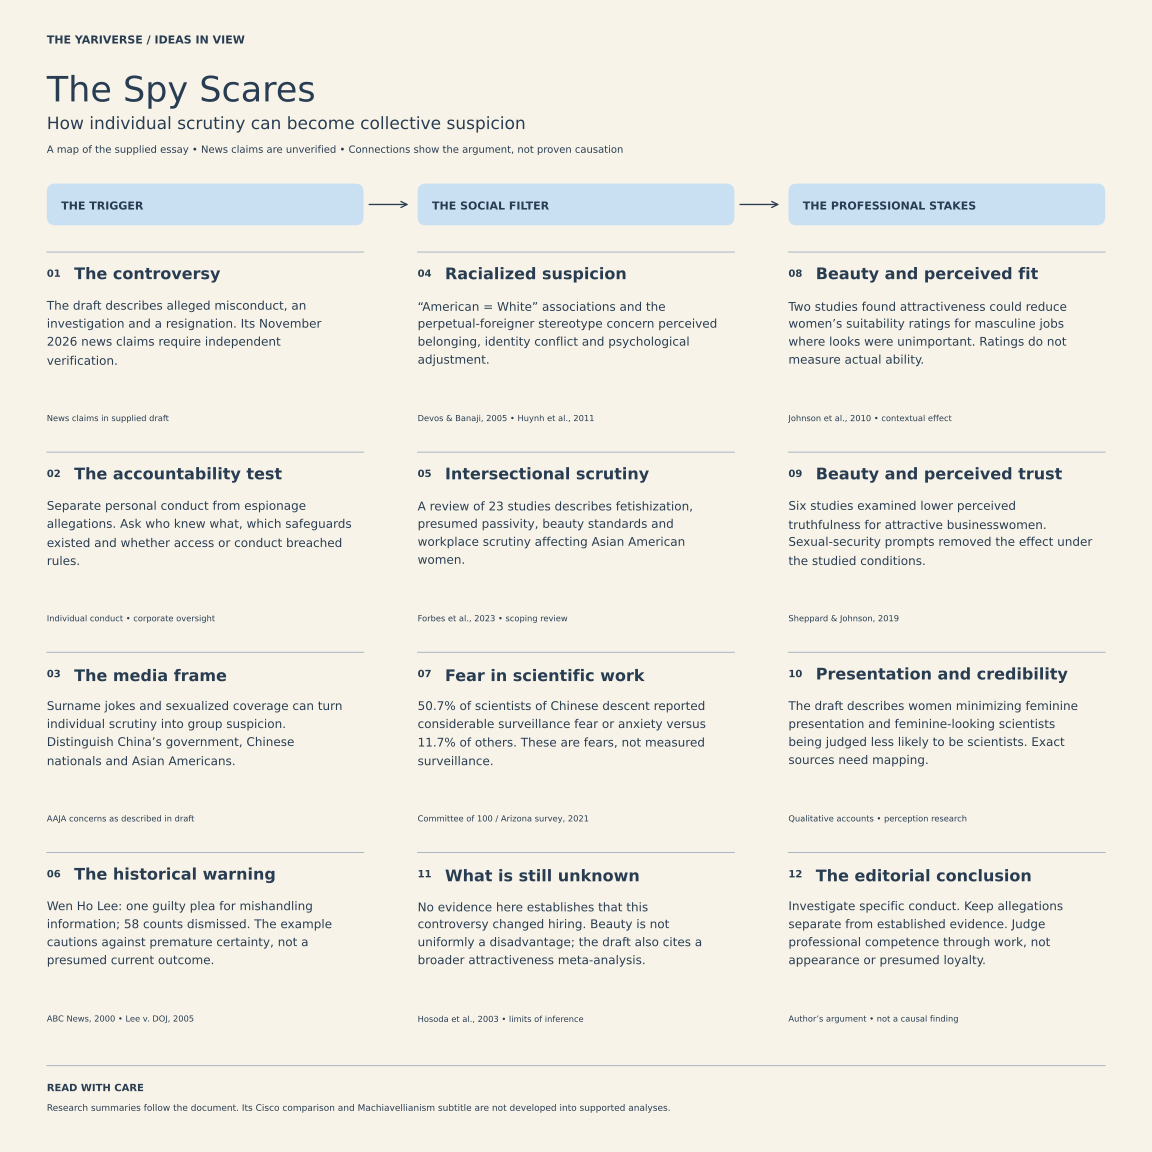

In [3]:
plt.rcParams.update({"font.family": "DejaVu Sans", "svg.fonttype": "none"})
fig, ax = plt.subplots(figsize=(16, 16))
fig.patch.set_facecolor(PALETTE["ivory"])
ax.set_facecolor(PALETTE["ivory"])
ax.set_xlim(0, 1600); ax.set_ylim(1600, 0); ax.axis("off")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
def label(x,y,text,size=12,weight="normal",color=None):
    return ax.text(x,y,text,fontsize=size,fontweight=weight,color=color or PALETTE["slate"],va="top",linespacing=1.5)
label(65,44,"THE YARIVERSE  /  IDEAS IN VIEW",11,"bold")
label(65,91,"The Spy Scares",35)
label(65,155,"How individual scrutiny can become collective suspicion",17)
label(65,198,"A map of the supplied essay • News claims are unverified • Connections show the argument, not proven causation",10)
# Each row groups related themes. Arrows link the three argument stages.
stages=[("THE TRIGGER",65),("THE SOCIAL FILTER",580),("THE PROFESSIONAL STAKES",1095)]
for title,x in stages:
    ax.add_patch(FancyBboxPatch((x,255),440,58,boxstyle="round,pad=0,rounding_size=12",facecolor=PALETTE["baby"],edgecolor="none"))
    label(x+20,274,title,11,"bold")
for x in [510,1025]:
    ax.add_patch(FancyArrowPatch((x,284),(x+60,284),arrowstyle="->",mutation_scale=15,color=PALETTE["slate"],lw=1.3))
# Read down each column; numbers preserve the essay’s broader sequence.
order = [[0,1,2,5],[3,4,6,10],[7,8,9,11]]
for col,indices in enumerate(order):
    x=65+515*col
    for row,idx in enumerate(indices):
        num,title,body,source=CARDS[idx]
        y=350+278*row
        ax.plot([x,x+440],[y,y],color=PALETTE["dusty"],lw=1)
        label(x,y+19,num,10,"bold")
        label(x+38,y+15,title,16,"bold")
        label(x,y+63,textwrap.fill(body,48),12)
        label(x,y+223,textwrap.fill(source,57),8.3)
ax.plot([65,1535],[1480,1480],color=PALETTE["dusty"],lw=1)
label(65,1500,"READ WITH CARE",10,"bold")
label(65,1530,"Research summaries follow the document. Its Cisco comparison and Machiavellianism subtitle are not developed into supported analyses.",9)
for ext in ("svg","png"):
    fig.savefig(OUTPUT_DIR / f"The_Spy_Scares_Diagram.{ext}", dpi=160, facecolor=PALETTE["ivory"])
plt.close(fig)
display(SVG(filename=str(OUTPUT_DIR / "The_Spy_Scares_Diagram.svg")))


In [ ]:
svg = (OUTPUT_DIR / "The_Red_Scares_Diagram.svg").read_text()
svg = svg[svg.index("<svg"):]
svg = re.sub(r'width="[^"]+"', 'width="100%"', svg, count=1)
svg = re.sub(r'height="[^"]+"', 'height="auto"', svg, count=1)
source_html = "".join("<p>"+html.escape(p)+"</p>" for p in SOURCE_PARAGRAPHS)
card_html = "".join("<article><h3>"+html.escape(c[1])+"</h3><p>"+html.escape(c[2])+"</p><small>"+html.escape(c[3])+"</small></article>" for c in CARDS)
page = """<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>The Huang Scares | The Yariverse</title>
<style>:root{--ivory:#F7F3E8;--baby:#C9DFF2;--slate:#293D52;--dusty:#A9B8C5}*{box-sizing:border-box}body{margin:0;background:var(--ivory);color:var(--slate);font:16px/1.7 Arial,sans-serif}main{max-width:1200px;margin:auto;padding:24px}nav{display:flex;justify-content:space-between;align-items:center;gap:20px}button{background:var(--baby);border:0;border-radius:24px;padding:12px 20px;color:var(--slate);cursor:pointer}svg{display:block;width:100%;height:auto}details{border-top:1px solid var(--dusty);padding:22px 0}summary{cursor:pointer;font-weight:bold}article{padding:12px 0;border-bottom:1px solid var(--dusty)}small{font-size:13px}#original{max-width:850px}p{overflow-wrap:anywhere}.note{font-size:14px}@media print{nav,details{display:none}main{padding:0;max-width:none}svg{width:100%}}@media(max-width:700px){main{padding:12px}.graphic{overflow-x:auto}.graphic svg{min-width:850px}}</style></head><body><main><nav><span>THE YARIVERSE</span><button onclick="window.print()">Print / Save as PDF</button></nav><div class="graphic" role="img" aria-label="Concept map of The Huang Scares: trigger, social filters, professional consequences, evidence limits and editorial conclusion.">""" + svg + """</div><p class="note">This is a visual adaptation of the supplied document, not independent verification of its reporting. Expand the sections below for readable summaries and the full original text and citations.</p><details><summary>Read every diagram theme</summary>"""+card_html+"""</details><details><summary>Original document and citations</summary><p><strong>Source text reproduced as supplied; allegations and current-event claims remain unverified.</strong></p><div id="original">"""+source_html+"""</div></details></main></body></html>"""
(OUTPUT_DIR / "The_Spy_Scares.html").write_text(page, encoding="utf-8")
print("Created SVG, PNG and self-contained HTML in", OUTPUT_DIR.resolve())
